# Time Series - Collection visuals

A collection can answer different questions, and each question has its own picture. Is there data, and when? How do different variables relate over time? Do several sites or model runs agree? This tutorial goes through the visuals of the time series collections from those questions, using a small synthetic catchment.

All visuals follow the same pattern: choose a `layout` in `view_specs`, adjust other specs if needed, and call `.view()`.

Covered here:

- Choosing a visual for each question
- Data availability: the `full` and `simple` layouts
- Stacked panels: the `stacked` and `stacked-simple` layouts
- Specs of the collection and specs of each series
- Common uses: rain, streamflow and storage; model and error; series decomposition
- Comparing series of the same variable: clusters and ensembles
- Saving a figure and adding to it

```{seealso}
Check out the {doc}`Time Series - Collections <timeseries_07_collection>` tutorial for how collections work.
```

## Which visual?

| Question | Object | Layout |
|---|---|---|
| When is there data, and where do records overlap? | any collection | `full`, `simple` |
| How do different variables behave over the same time? | any collection | `stacked`, `stacked-simple` |
| Do sites of the same variable agree? | `TimeSeriesCluster` | `series`, `series-simple` |
| How similar are the sites, as numbers? | `TimeSeriesCluster` | `correlation` |
| What is the spread of many realizations? | `TimeSeriesEnsemble` | `series`, `series-simple` |
| How does the year vary, and how does this year compare? | `SeasonalEnsemble` | `series`, `series-simple` |

The `-simple` layouts leave out the histograms and CDFs, which gives the time axis the full width of the figure.

## Notebook setup

For users running this tutorial as a Jupyter Notebook, this cell must be executed first:

In [1]:
import sys
import numpy as np
import pandas as pd

# Install `plans` in `google.colab`.
# Use `pip install plans` for other environments.

if "google.colab" in sys.modules:
    import os
    os.system(f"{sys.executable} -m pip install -q plans")

from plans.datasets import (
    ETSeries,
    PETSeries,
    RainSeries,
    StreamflowSeries,
    TemperatureSeries,
    TimeSeries,
    TimeSeriesCluster,
    TimeSeriesCollection,
)

# This avoids warnings related to uninstalled fonts
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

rng = np.random.default_rng(seed=7)  # ensure reproducibility

## A synthetic catchment

Rain and potential evapotranspiration come from the generators of each series. A simple water balance turns them into evapotranspiration, streamflow and storage: the catchment is a single reservoir, which loses water in proportion to how much it holds. The observed streamflow is the simulated one with some measurement error, and two measurement gaps.

In [2]:
start, end = "2018-01-01", "2021-12-31"
df_rain = RainSeries(name="Rain").generate(start=start, end=end, seed=1)
df_pet = PETSeries(name="PET").generate(start=start, end=end, seed=2)

# water balance of a single reservoir
n = len(df_rain)
vct_et, vct_q, vct_s = np.zeros(n), np.zeros(n), np.zeros(n)
storage = 100.0
for i in range(n):
    vct_et[i] = df_pet["pet"].values[i] * min(1, storage / 150)
    vct_q[i] = 0.05 * storage
    storage = max(0, storage + df_rain["ppt"].values[i] - vct_et[i] - vct_q[i])
    vct_s[i] = storage

df = pd.DataFrame(
    {
        "datetime": df_rain["datetime"],
        "Rain": df_rain["ppt"],
        "PET": df_pet["pet"],
        "ET": vct_et,
        "Simulated": vct_q,
        "Observed": vct_q * rng.lognormal(mean=0, sigma=0.15, size=n),
        "Storage": vct_s,
    }
)

# measurement gaps
df.loc[df["datetime"].between("2019-04-01", "2019-08-15"), "Observed"] = np.nan
df.loc[df["datetime"].between("2020-11-01", "2020-12-10"), "Observed"] = np.nan
df["Error"] = df["Simulated"] - df["Observed"]
df.head()

,datetime,Rain,PET,ET,Simulated,Observed,Storage,Error
0,2018-01-01,10.285795,5.558449,3.705633,5.000000,5.000923,101.580162,-0.000923
1,2018-01-02,11.431808,5.318397,3.601624,5.079008,5.311784,104.331337,-0.232776
2,2018-01-03,10.970837,5.217987,3.629331,5.216567,5.006409,106.456276,0.210158
3,2018-01-04,7.791624,4.352178,3.088778,5.322814,4.657195,105.836309,0.665619
4,2018-01-05,10.755277,5.514332,3.890777,5.291815,4.942942,107.408994,0.348873


Each column goes into a series of its own class, which brings the variable name and the units. Gaps stay as empty rows, so lines break there. With `dropnan=True`, these rows are dropped and a line goes straight across a gap, until `.standardize()` brings them back. There is no class for storage or errors, so these two are plain `TimeSeries`. The temperature is independent of the rest, and starts a year later, so the next section has something to show.

Note that `.append()` stores a copy of the series. To change a series afterwards, reach it through `tsc.collection[name]`.

In [3]:
def make_series(name, cls=TimeSeries, varname=None):
    ts = cls(name=name, alias=name[:3])
    if varname is not None:
        ts.varname = varname
        ts.units = "mm"
    ts.set_data(input_df=df, input_dtfield="datetime", input_varfield=name)
    return ts

tsc = TimeSeriesCollection(name="Catchment")
for ts in [
    make_series(name="Rain", cls=RainSeries),
    make_series(name="PET", cls=PETSeries),
    make_series(name="ET", cls=ETSeries),
    make_series(name="Simulated", cls=StreamflowSeries),
    make_series(name="Observed", cls=StreamflowSeries),
    make_series(name="Error", varname="Error"),
    make_series(name="Storage", varname="Storage"),
]:
    tsc.append(new_object=ts)

# a shorter record
ts_tas = TemperatureSeries(name="Temperature", alias="Tem")
ts_tas.generate(start="2019-01-01", end=end, seed=3, inplace=True)
tsc.append(new_object=ts_tas)

tsc.update(details=True)
tsc.catalog[["name", "alias", "units", "start", "end"]]

,name,alias,units,start,end
0,ET,ET,mm,2018-01-01,2021-12-31
1,Error,Err,mm,2018-01-01,2021-12-31
2,Observed,Obs,mm,2018-01-01,2021-12-31
3,PET,PET,mm,2018-01-01,2021-12-31
4,Rain,Rai,mm,2018-01-01,2021-12-31
5,Simulated,Sim,mm,2018-01-01,2021-12-31
6,Storage,Sto,mm,2018-01-01,2021-12-31
7,Temperature,Tem,Celsius,2019-01-01,2021-12-31


## When is there data?

The default `full` layout does not draw any values. It is a map of the records, usually the first thing to check in a new dataset. The Gantt chart (a) has a bar for each continuous stretch of each series, so gaps show as breaks. The overlap (b) gives the share of series with data at each time, and the prevalence (c) gives the share of the whole period that each series covers.

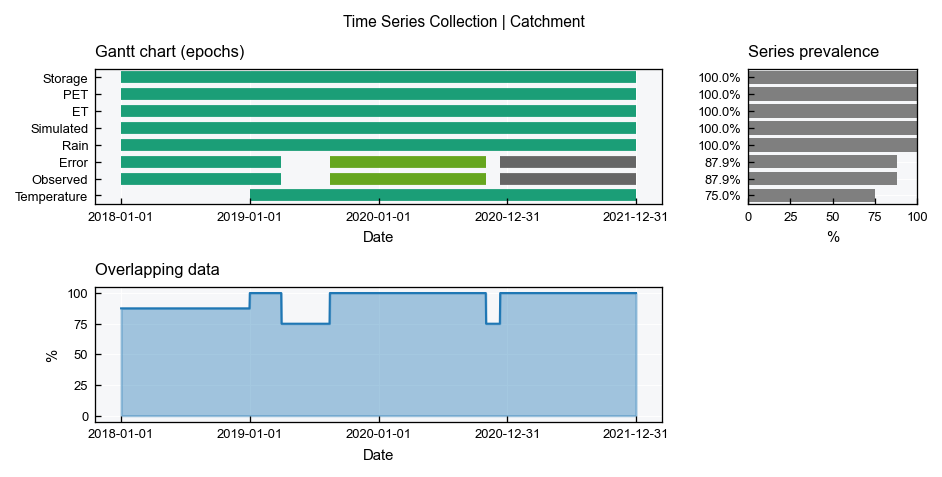

In [4]:
tsc.view()

The observed streamflow shows its two gaps, and the temperature starts late. The drop in the overlap marks the periods where any analysis combining these series loses data. The `simple` layout leaves out the prevalence, and `usealias` swaps names for aliases, which helps with long names:

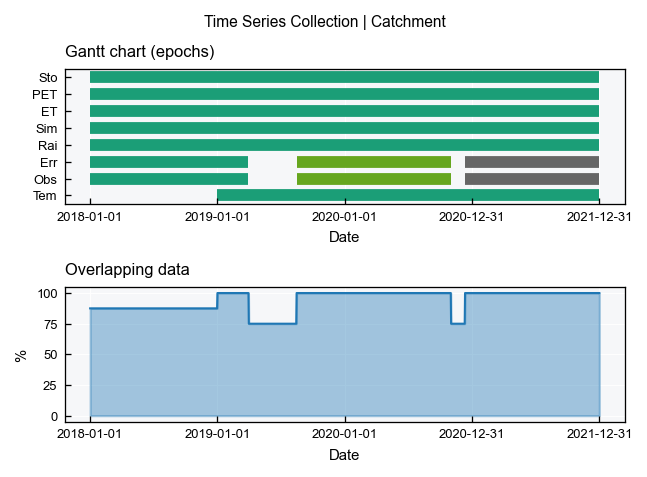

In [5]:
tsc.view_specs["layout"] = "simple"
tsc.view_specs["usealias"] = True
tsc.view()
tsc.view_specs["usealias"] = False

## Stacked panels

The `stacked` layout draws one panel per row with a common time axis, so events line up from top to bottom. Each row has the series, its histogram and its CDF, just like the view of a single series.

The `panels` spec tells which series go where, as a list with the names of each panel. Here is the classic reading of a catchment, where rain drives storage and storage drives streamflow:

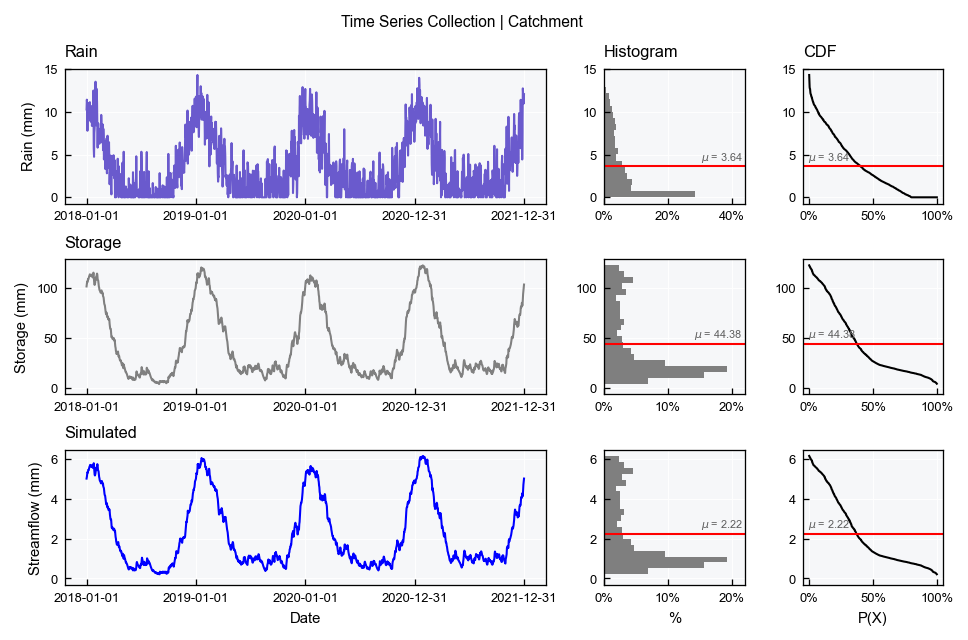

In [6]:
tsc.view_specs["layout"] = "stacked"
tsc.view_specs["panels"] = [["Rain"], ["Storage"], ["Simulated"]]
tsc.view()

With `panels` set to `None`, which is the default, each series of the collection gets its own panel, in the order of the catalog. The height of the figure follows the number of panels, so this gets tall quickly.

### Several series on a panel

A panel takes any number of series. Their histograms and CDFs are overlaid, using common bins so they can be compared, and the mean lines become dashed. A legend appears at the top of the panel. Each series uses its own `color`, so here the observed streamflow goes in black to stand out from the simulated one:

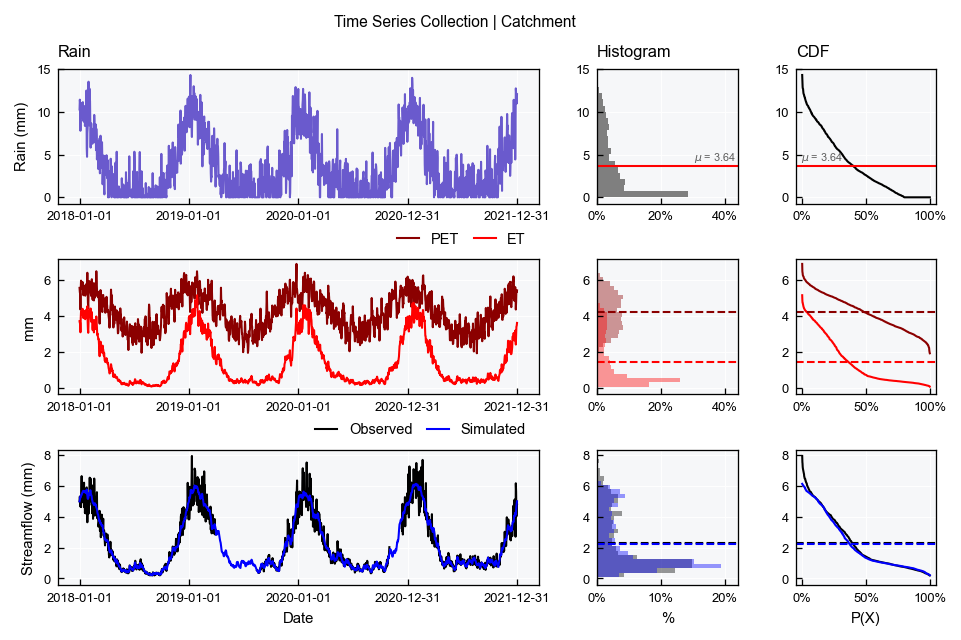

In [7]:
tsc.collection["Observed"].view_specs["color"] = "black"

tsc.view_specs["panels"] = [["Rain"], ["PET", "ET"], ["Observed", "Simulated"]]
tsc.view()

ET follows PET when the reservoir is full and falls behind it when the reservoir runs low, which is hard to see in separate panels. The gaps of the observed series simply show as breaks in the line.

Series in a panel share one y axis, so they must have the same units. A mix raises an error rather than producing a misleading figure:

In [8]:
tsc.view_specs["panels"] = [["Rain", "Temperature"]]
try:
    tsc.view()
except ValueError as e:
    print(e)

Series of a panel must have the same units. Got {'Rain': 'mm', 'Temperature': 'Celsius'}


### Heights of the panels

Panels have equal heights by default. The `panel_heights` spec sets relative heights, which helps when one panel is the main subject. A model and its error is the typical case:

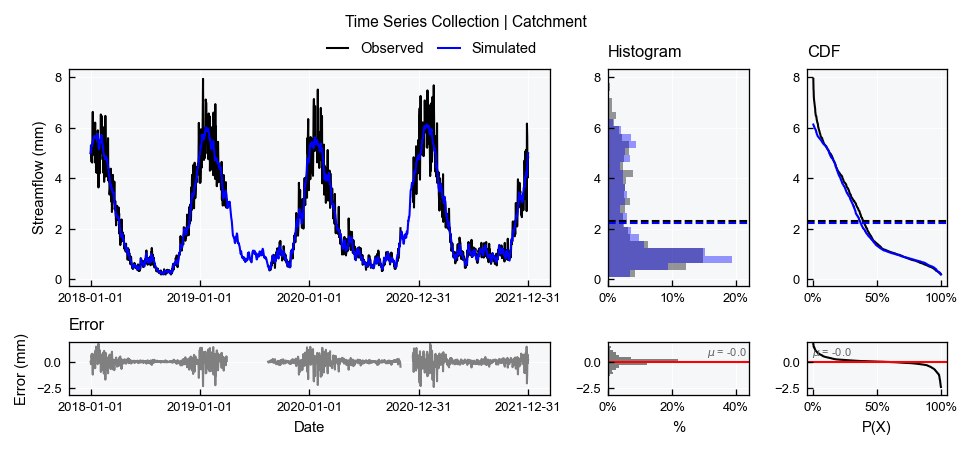

In [9]:
tsc.view_specs["panels"] = [["Observed", "Simulated"], ["Error"]]
tsc.view_specs["panel_heights"] = [3, 1]
tsc.view()

This spec stays in `view_specs`, like all others. It must have one value per panel, so remember to reset it when changing the panels.

### Series only

The `stacked-simple` layout leaves out the histograms and CDFs. It suits long records and many panels, where the width helps more than the distributions do. The `xmin` and `xmax` specs zoom into a period:

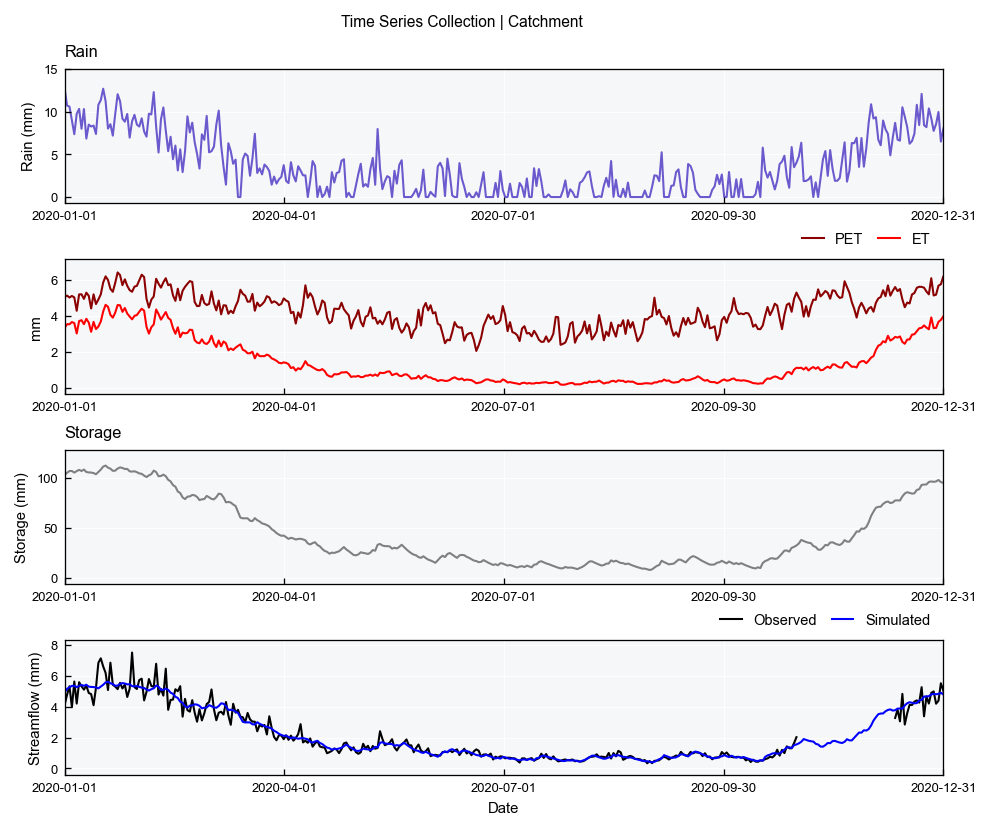

In [10]:
tsc.view_specs["layout"] = "stacked-simple"
tsc.view_specs["panel_heights"] = None
tsc.view_specs["panels"] = [["Rain"], ["PET", "ET"], ["Storage"], ["Observed", "Simulated"]]
tsc.view_specs["xmin"] = pd.Timestamp("2020-01-01")
tsc.view_specs["xmax"] = pd.Timestamp("2020-12-31")
tsc.view()

```{note}
The `xmin` and `xmax` specs only change the time axis. In the `stacked` layout, histograms, CDFs and the y axis still describe the whole record. To get those for a period, filter the data of the series first.
```

## Two levels of specs

A stacked figure takes specs from two places. The collection decides the figure, and each series decides its own look, in its own `view_specs`.

| Where | Spec | What it does |
|---|---|---|
| Collection | `layout`, `panels`, `panel_heights` | The structure of the figure |
| Collection | `title`, `xlabel`, `subtitle_hist`, `subtitle_cdf` | Texts |
| Collection | `xmin`, `xmax` | The period |
| Collection | `usealias` | Aliases instead of names, in titles and legends |
| Collection | `bins`, `alpha_hist`, `histtype`, `plot_mean` | Histograms and means of **shared** panels |
| Collection | `cmap_series` | Where a replacement color comes from |
| Series | `color`, `linewidth`, `alpha` | The line |
| Series | `fill`, `fill_only`, `color_fill` | The area below the line |
| Series | `color_hist`, `color_cdf`, `color_mean`, `bins` | Histogram, CDF and mean of a **lone** series |
| Series | `range` | The y range. A shared panel covers the ranges of all its series |

Here is rain as a filled area, in a fixed range, next to a streamflow in blue:

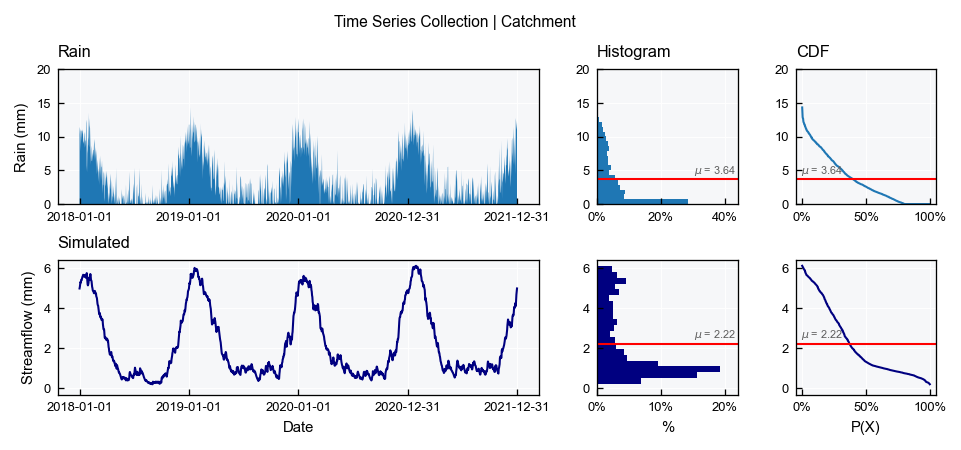

In [11]:
ts_rain = tsc.collection["Rain"]
ts_rain.view_specs["color"] = "tab:blue"
ts_rain.view_specs["color_hist"] = "tab:blue"
ts_rain.view_specs["color_cdf"] = "tab:blue"
ts_rain.view_specs["fill"] = True
ts_rain.view_specs["fill_only"] = True
ts_rain.view_specs["range"] = [0, 20]

ts_flow = tsc.collection["Simulated"]
ts_flow.view_specs["color"] = "navy"
ts_flow.view_specs["color_hist"] = "navy"
ts_flow.view_specs["color_cdf"] = "navy"

tsc.view_specs["layout"] = "stacked"
tsc.view_specs["xmin"] = None
tsc.view_specs["xmax"] = None
tsc.view_specs["panels"] = [["Rain"], ["Simulated"]]
tsc.view()

A shared panel uses the `color` of each series for the line, histogram, CDF and mean together. If two series of a panel have the same color, as the ones of the same class do by default, the repeated one takes the color of `cmap_series` farthest from those in use.

## Series decomposition

The panels do not need to come from different sensors. A decomposition splits one series into parts that add up to it, and stacked panels read naturally for that. Here it is for twenty years of temperature with a warming trend. The trend comes from a centered moving average, the cycle from the average of each day of the year, and the remainder from what is left:

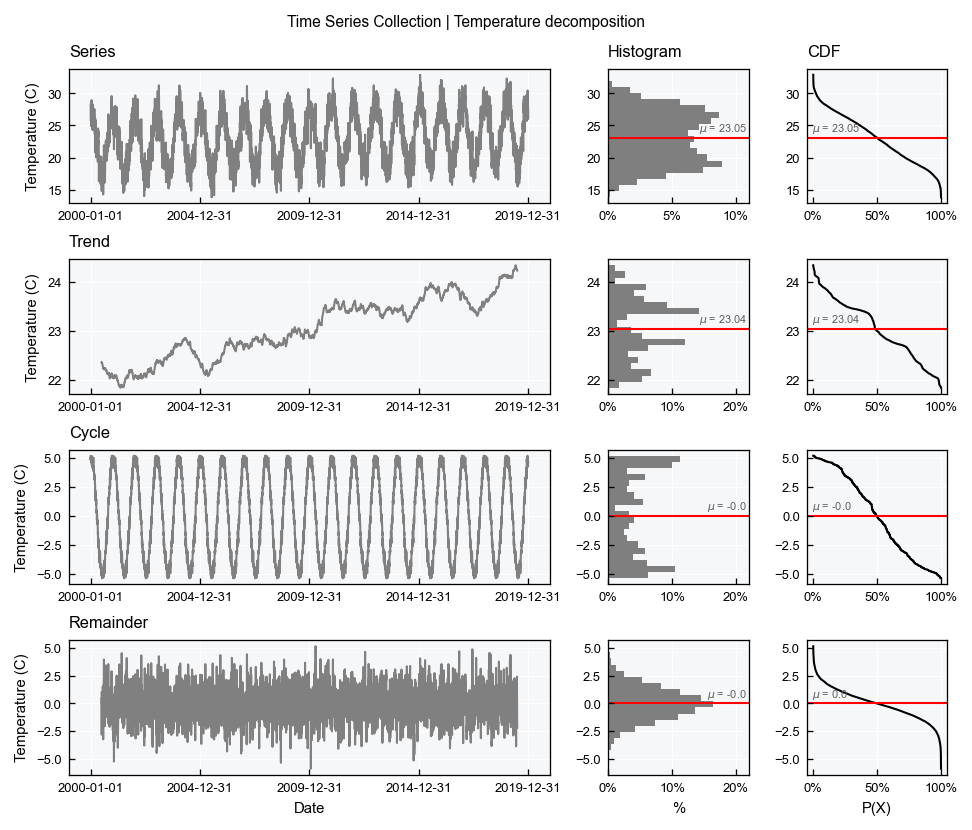

In [12]:
ts_warm = TemperatureSeries(name="Warming")
ts_warm.generator_specs["change_per_year"] = 0.1
df_t = ts_warm.generate(start="2000-01-01", end="2019-12-31", seed=4)

df_t["Trend"] = df_t["tas"].rolling(window=365, center=True).mean()
vct_doy = df_t["datetime"].dt.dayofyear
df_t["Cycle"] = (df_t["tas"] - df_t["Trend"]).groupby(vct_doy).transform("mean")
df_t["Remainder"] = df_t["tas"] - df_t["Trend"] - df_t["Cycle"]
df_t["Series"] = df_t["tas"]

tsc_parts = TimeSeriesCollection(name="Temperature decomposition")
for name in ["Series", "Trend", "Cycle", "Remainder"]:
    ts = TimeSeries(name=name, alias=name)
    ts.varname = "Temperature"
    ts.units = "C"
    ts.set_data(input_df=df_t, input_dtfield="datetime", input_varfield=name)
    tsc_parts.append(new_object=ts)
tsc_parts.update(details=True)

tsc_parts.view_specs["layout"] = "stacked"
tsc_parts.view_specs["panels"] = [["Series"], ["Trend"], ["Cycle"], ["Remainder"]]
tsc_parts.view()

The catalog sorts the names alphabetically, so the `panels` spec is also how to set the reading order. Note how each panel keeps its own y range: the trend is much smaller than the cycle, but both fill their panels. Read the values on the axes before comparing the size of the parts. The trend and the remainder are also shorter than the series, as the moving average needs a full window on both sides.

## Series of the same variable

Some collections hold one variable only, and their series can share a single axis. The `TimeSeriesCluster` is for different sites, and adds the `series`, `series-simple` and `correlation` layouts. Here is a small network of rain gauges:

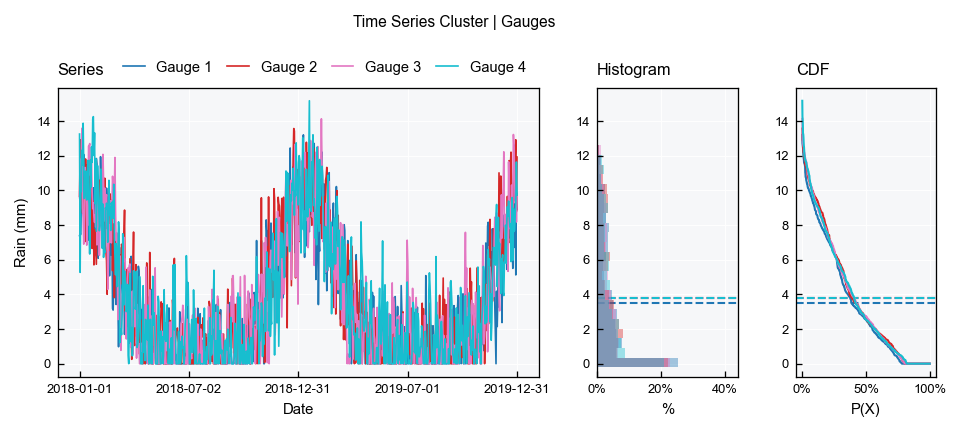

In [13]:
tsc_gauges = TimeSeriesCluster(name="Gauges", base_object=RainSeries)
for i in range(4):
    name = f"Gauge {i + 1}"
    ts = RainSeries(name=name, alias=f"G{i + 1}")
    ts.generate(start=start, end="2019-12-31", seed=10 + i, inplace=True)
    tsc_gauges.append(new_object=ts)
tsc_gauges.update(details=True)

tsc_gauges.view_specs["layout"] = "series"
tsc_gauges.view()

With many series, the `highlight` spec keeps a few in color and sends the others to the background:

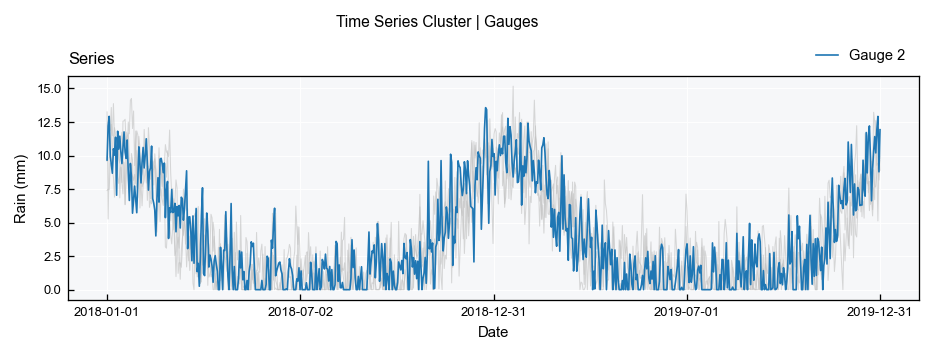

In [14]:
tsc_gauges.view_specs["layout"] = "series-simple"
tsc_gauges.view_specs["highlight"] = ["Gauge 2"]
tsc_gauges.view()

The `correlation` layout gives the same comparison as numbers. The weather of these gauges is independent, and they only share the cycle, which is already enough for high values:

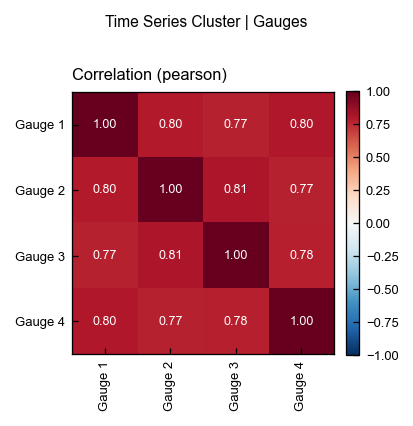

In [15]:
tsc_gauges.view_specs["layout"] = "correlation"
tsc_gauges.view()

A `TimeSeriesEnsemble` is for many realizations of one series, like model runs. Its `series` layout draws the members in the background, with percentile bands and statistics on top. A `SeasonalEnsemble` does the same with the years of a single series, and it comes straight from the series:

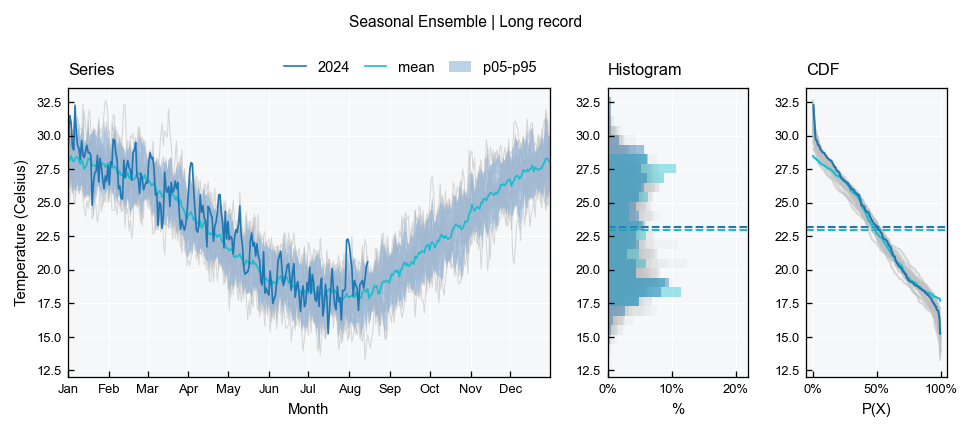

In [16]:
ts_long = TemperatureSeries(name="Long record")
ts_long.generate(start="2000-01-01", end="2024-08-15", seed=1, inplace=True)

se = ts_long.get_seasonal_ensemble()
se.view_specs["highlight"] = ["2024"]
se.view()

```{seealso}
These objects have their own tutorials: {doc}`Time Series - Clusters <timeseries_08_cluster>`, {doc}`Time Series - Ensembles <timeseries_10_ensemble>` and {doc}`Time Series - Seasonal ensembles <timeseries_11_seasonal>`.
```

## Saving a figure and adding to it

With `show=False`, the `.view()` method saves the figure instead of showing it. The file is `{folder}/{filename}.{fig_format}`, from the specs of the same names, and the folder must exist:

```python
tsc.view_specs["folder"] = "./outputs"
tsc.view_specs["filename"] = "catchment"
tsc.view_specs["fig_format"] = "png"
tsc.view(show=False)
```

With `return_fig=True`, it returns the matplotlib figure, for adding things that the specs do not cover. The axes come panel by panel, and each panel of the `stacked` layout has three: series, histogram and CDF. Here is the zero line of the error, and a mark on a date of interest:

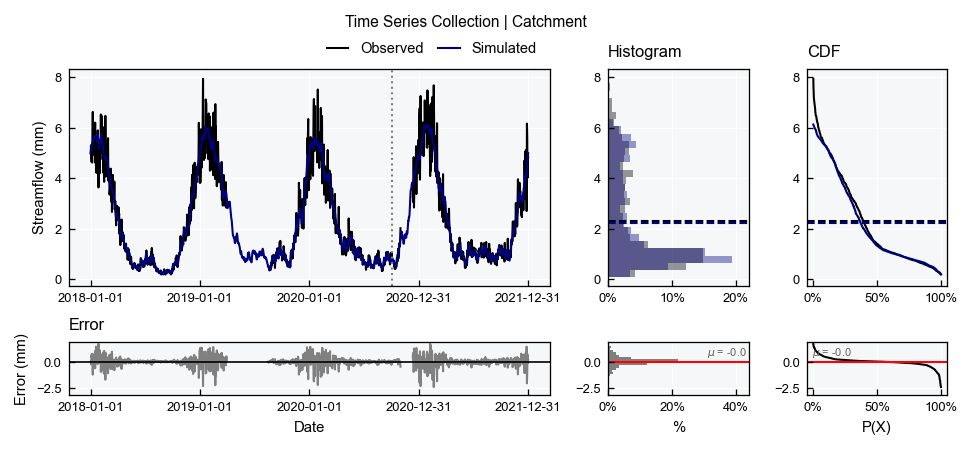

In [17]:
tsc.view_specs["panels"] = [["Observed", "Simulated"], ["Error"]]
tsc.view_specs["panel_heights"] = [3, 1]
fig = tsc.view(return_fig=True)

ax_flow, ax_error = fig.get_axes()[0], fig.get_axes()[3]
ax_error.axhline(y=0, color="black", linewidth=0.8)
ax_flow.axvline(x=pd.Timestamp("2020-10-01"), color="gray", linestyle="dotted");

## Recap

- The `layout` spec chooses the visual, and the class decides which layouts are available. An unknown layout raises an error that lists the options.
- `full` and `simple` show when there is data, and `stacked` and `stacked-simple` show the values on a common time axis.
- `panels` sets which series go in each panel, `panel_heights` sets their relative sizes, and series in a panel must have the same units.
- The collection specs decide the figure, and the specs of each series decide its look.
- Clusters and ensembles add the `series` layouts, where series of one variable share an axis.
- `return_fig=True` gives the matplotlib figure, for anything else.